# Wide Residual Networks

**Paper:** [arXiv:1605.07146](https://arxiv.org/abs/1605.07146)
**Authors:** Sergey Zagoruyko, Nikos Komodakis (BMVC 2016)

In 2016 the race in image classification was to go **deeper**: ResNets with 152, then 1001 layers. This paper asked a
simple question: what if we make residual networks **wider** instead? The paper reports that a wide 16-layer network can
match a 1000-layer thin ResNet and train several times faster.

This notebook tests that idea at small scale **on real CIFAR-10, from scratch, on one Kaggle T4 GPU** (it does not train a 1000-layer ResNet):

1. **Width vs. depth race:** 7 WRNs trained with an identical recipe: 4 that grow *wider* (WRN-16-1/2/4/8) and 4 that grow *deeper* (WRN-16/28/40/52-1).
2. **Accuracy vs. parameters and vs. wall-clock time:** where width and depth spend their budget.
3. **A ~94% CIFAR-10 model in minutes:** WRN-16-8 trained from scratch.
4. **Lesion study, i.e. "diminishing feature reuse" made visible:** switch off one residual block at a time and see how much each block actually matters in a deep-thin vs. a wide network.
5. **What the network sees:** predictions, its most confident mistakes, and a confusion matrix.

The model is the paper's exact WRN-n-k architecture: pre-activation basic blocks `B(3,3)`, three groups of widths
`16k, 32k, 64k`, `(n−4)/6` blocks per group. Simplifications are listed at the end.

## 1. Setup

In [1]:
import time, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

# One shared training recipe for every model so that the comparison is fair
EPOCHS = 20
BATCH_SIZE = 256
PEAK_LR = 0.2
WEIGHT_DECAY = 5e-4        # paper's value
MOMENTUM = 0.9             # paper: SGD with Nesterov momentum 0.9
LABEL_SMOOTHING = 0.1
USE_AMP = DEVICE.type == 'cuda'

WIDE_CONFIGS = [(16, 1), (16, 2), (16, 4), (16, 8)]    # same depth, growing width
DEEP_CONFIGS = [(16, 1), (28, 1), (40, 1), (52, 1)]    # same width, growing depth
CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Device: cuda
GPU: Tesla T4


## 2. CIFAR-10, Kept Entirely on the GPU

The whole dataset (50k + 10k images of 32×32) is only ~180 MB, so we load it once as `uint8` tensors on the GPU and do
the paper's augmentation (**4-pixel padding + random 32×32 crop + horizontal flip**) on the GPU in a batched way. This
removes the CPU data-loader bottleneck, so the timings below measure the networks rather than the input pipeline.

Loading CIFAR-10 (downloads ~170 MB on first run)...


Loaded CIFAR-10 in 3.1s | train (50000, 3, 32, 32) | test (10000, 3, 32, 32)


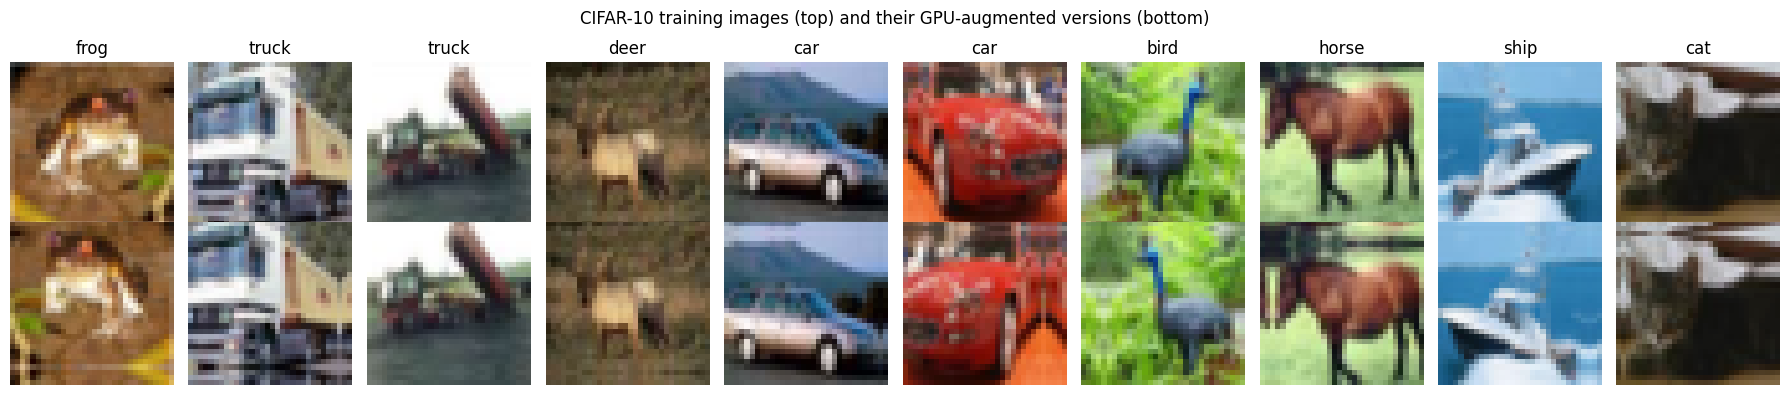

In [2]:
import os

# On Kaggle, attach the CIFAR-10 Python dataset (pankrzysiu/cifar10-python) to skip the slow download;
# anywhere else torchvision downloads it
KAGGLE_CIFAR = '/kaggle/input/cifar10-python'
CIFAR_ROOT = KAGGLE_CIFAR if os.path.isdir(KAGGLE_CIFAR + '/cifar-10-batches-py') else './data'

def load_cifar(train):
    ds = torchvision.datasets.CIFAR10(root=CIFAR_ROOT, train=train, download=True)
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()     # (N, 3, 32, 32) uint8
    y = torch.tensor(ds.targets, dtype=torch.long)
    return x, y

print('Loading CIFAR-10 (downloads ~170 MB on first run)...', flush=True)
t0 = time.time()
x_train_u8, y_train = load_cifar(True)
x_test_u8, y_test = load_cifar(False)
print(f'Loaded CIFAR-10 in {time.time() - t0:.1f}s | train {tuple(x_train_u8.shape)} | test {tuple(x_test_u8.shape)}')

MEAN = x_train_u8.float().mean(dim=(0, 2, 3)).view(1, 3, 1, 1) / 255
STD = x_train_u8.float().std(dim=(0, 2, 3)).view(1, 3, 1, 1) / 255
x_train_gpu, y_train_gpu = x_train_u8.to(DEVICE), y_train.to(DEVICE)
x_test_gpu, y_test_gpu = x_test_u8.to(DEVICE), y_test.to(DEVICE)
MEAN, STD = MEAN.to(DEVICE), STD.to(DEVICE)


def normalize(x_u8):
    return ((x_u8.float() / 255) - MEAN) / STD


def augment(x):
    # Batched random crop with 4-px reflect padding + horizontal flip, all on the GPU
    n = x.shape[0]
    padded = F.pad(x, (4, 4, 4, 4), mode='reflect')
    dx = torch.randint(0, 9, (n,), device=x.device)
    dy = torch.randint(0, 9, (n,), device=x.device)
    ar = torch.arange(32, device=x.device)
    rows = (dy[:, None] + ar[None]).view(n, 1, 32, 1).expand(n, 3, 32, 32)
    cols = (dx[:, None] + ar[None]).view(n, 1, 1, 32).expand(n, 3, 32, 32)
    out = padded[torch.arange(n, device=x.device)[:, None, None, None], torch.arange(3, device=x.device)[None, :, None, None], rows, cols]
    flip = torch.rand(n, device=x.device) < 0.5
    out[flip] = out[flip].flip(-1)
    return out


fig, axes = plt.subplots(2, 10, figsize=(18, 4))
sample = x_train_gpu[:10]
aug = augment(normalize(sample))
for i in range(10):
    axes[0, i].imshow(sample[i].permute(1, 2, 0).cpu()); axes[0, i].set_title(CLASSES[y_train[i]]); axes[0, i].axis('off')
    a = (aug[i] * STD[0] + MEAN[0]).clamp(0, 1)
    axes[1, i].imshow(a.permute(1, 2, 0).cpu()); axes[1, i].axis('off')
axes[0, 0].set_ylabel('original'); axes[1, 0].set_ylabel('augmented')
plt.suptitle('CIFAR-10 training images (top) and their GPU-augmented versions (bottom)')
plt.tight_layout(); plt.show()

## 3. The WRN-n-k Architecture

The paper's block `B(3,3)` is a **pre-activation** residual block (BN → ReLU → conv3×3 → BN → ReLU → conv3×3), with an
optional dropout between the two convolutions. A WRN-n-k is:

| group | output size | block | repeats |
|---|---|---|---|
| conv1 | 32×32 | 3×3, 16 | 1 |
| conv2 | 32×32 | B(3,3) with **16·k** channels | N |
| conv3 | 16×16 | B(3,3) with **32·k** channels | N |
| conv4 | 8×8 | B(3,3) with **64·k** channels | N |
| head | 1×1 | BN-ReLU, global avg-pool, FC | 1 |

with `N = (n − 4) / 6`. With `k = 1` this is a standard thin pre-activation ResNet. The only difference between
"deep" and "wide" models below is `n` vs. `k`.

In [3]:
class WideBasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride, dropout=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.shortcut = None
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Conv2d(c_in, c_out, 1, stride, 0, bias=False)
        self.enabled = True     # used by the lesion study: False -> keep only the shortcut path

    def forward(self, x):
        o = F.relu(self.bn1(x))
        identity = x if self.shortcut is None else self.shortcut(o)
        if not self.enabled:
            return identity
        out = self.conv1(o)
        out = self.conv2(self.dropout(F.relu(self.bn2(out))))
        return identity + out


class WideResNet(nn.Module):
    def __init__(self, depth, k, num_classes=10, dropout=0.0):
        super().__init__()
        assert (depth - 4) % 6 == 0, 'depth must be 6N + 4'
        n = (depth - 4) // 6
        widths = [16, 16 * k, 32 * k, 64 * k]
        self.name = f'WRN-{depth}-{k}'
        self.conv1 = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False)
        blocks, c_in = [], widths[0]
        for g, (w, stride) in enumerate(zip(widths[1:], [1, 2, 2])):
            for b in range(n):
                blocks.append(WideBasicBlock(c_in, w, stride if b == 0 else 1, dropout))
                c_in = w
        self.blocks = nn.Sequential(*blocks)
        self.bn = nn.BatchNorm2d(c_in)
        self.fc = nn.Linear(c_in, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        x = self.blocks(self.conv1(x))
        x = F.relu(self.bn(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


def count_params(m):
    return sum(p.numel() for p in m.parameters())


print(f'{"model":10s} {"blocks":>6s} {"params":>10s}')
for d, k in sorted(set(WIDE_CONFIGS + DEEP_CONFIGS)):
    m = WideResNet(d, k)
    print(f'{m.name:10s} {len(m.blocks):6d} {count_params(m) / 1e6:9.2f}M')

model      blocks     params
WRN-16-1        6      0.18M
WRN-16-2        6      0.69M
WRN-16-4        6      2.75M


WRN-16-8        6     10.96M
WRN-28-1       12      0.37M
WRN-40-1       18      0.56M
WRN-52-1       24      0.76M


## 4. One Training Recipe for Every Model

SGD with Nesterov momentum 0.9 and weight decay 5e-4, as in the paper, but with a one-cycle learning-rate schedule and
20 epochs instead of 200 (see the simplifications). Mixed precision and `channels_last` memory format make good use of
the T4's tensor cores. Each run records test accuracy after every epoch together with the **wall-clock time**, so we
can compare models by how fast they learn, not only by how good they get.

In [4]:
@torch.no_grad()
def evaluate(model, bs=1000):
    model.eval()
    correct, logits_all = 0, []
    for s in range(0, len(x_test_gpu), bs):
        x = normalize(x_test_gpu[s:s + bs]).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(x)
        logits_all.append(logits.float())
        correct += (logits.argmax(1) == y_test_gpu[s:s + bs]).sum().item()
    return correct / len(x_test_gpu), torch.cat(logits_all)


def train(depth, k, epochs=EPOCHS, dropout=0.0, seed=SEED):
    torch.manual_seed(seed)
    model = WideResNet(depth, k, dropout=dropout).to(DEVICE).to(memory_format=torch.channels_last)
    opt = torch.optim.SGD(model.parameters(), lr=PEAK_LR, momentum=MOMENTUM, nesterov=True, weight_decay=WEIGHT_DECAY)
    steps_per_epoch = len(x_train_gpu) // BATCH_SIZE
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=PEAK_LR, total_steps=epochs * steps_per_epoch,
                                                pct_start=0.25, anneal_strategy='linear')
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    hist = {'time': [], 'acc': [], 'loss': []}
    elapsed = 0.0
    for ep in range(epochs):
        model.train()
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        t0 = time.time()
        perm = torch.randperm(len(x_train_gpu), device=DEVICE)
        tot = 0.0
        for i in range(steps_per_epoch):
            idx = perm[i * BATCH_SIZE:(i + 1) * BATCH_SIZE]
            x = augment(normalize(x_train_gpu[idx])).contiguous(memory_format=torch.channels_last)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = F.cross_entropy(model(x), y_train_gpu[idx], label_smoothing=LABEL_SMOOTHING)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() if i % 20 == 0 else 0.0
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        elapsed += time.time() - t0               # training time only, evaluation excluded
        acc, _ = evaluate(model)
        hist['time'].append(elapsed); hist['acc'].append(acc); hist['loss'].append(tot / math.ceil(steps_per_epoch / 20))
        if (ep + 1) % 5 == 0:
            print(f'  {model.name} epoch {ep + 1:2d}/{epochs} | test acc {acc * 100:5.2f}% | {elapsed:6.1f}s so far', flush=True)
    return model, hist

## 5. The Race: Wider vs. Deeper

All seven networks are trained with exactly the same recipe and number of epochs. `WRN-16-1` is shared by both
families: it is the thin, shallow starting point that one family makes wider and the other makes deeper.

In [5]:
results, models = {}, {}
t_all = time.time()
for d, k in sorted(set(WIDE_CONFIGS + DEEP_CONFIGS), key=lambda c: (c[1], c[0])):
    model, hist = train(d, k)
    name = model.name
    results[name] = {'depth': d, 'k': k, 'params': count_params(model), **hist}
    models[name] = model
    print(f'{name:9s} | {count_params(model) / 1e6:5.2f}M params | {len(model.blocks):2d} blocks | '
          f'test acc {hist["acc"][-1] * 100:5.2f}% | train time {hist["time"][-1]:6.1f}s '
          f'({hist["time"][-1] / EPOCHS:4.1f}s/epoch)')
print(f'\nAll runs finished in {(time.time() - t_all) / 60:.1f} min')

  WRN-16-1 epoch  5/20 | test acc 64.32% |   19.0s so far


  WRN-16-1 epoch 10/20 | test acc 77.55% |   32.8s so far


  WRN-16-1 epoch 15/20 | test acc 80.03% |   46.5s so far


  WRN-16-1 epoch 20/20 | test acc 88.66% |   60.4s so far


WRN-16-1  |  0.18M params |  6 blocks | test acc 88.66% | train time   60.4s ( 3.0s/epoch)


...

  WRN-16-8 epoch  5/20 | test acc 71.42% |  155.3s so far


  WRN-16-8 epoch 10/20 | test acc 83.89% |  306.5s so far


  WRN-16-8 epoch 15/20 | test acc 89.54% |  456.6s so far


  WRN-16-8 epoch 20/20 | test acc 94.18% |  605.9s so far


WRN-16-8  | 10.96M params |  6 blocks | test acc 94.18% | train time  605.9s (30.3s/epoch)

All runs finished in 24.4 min


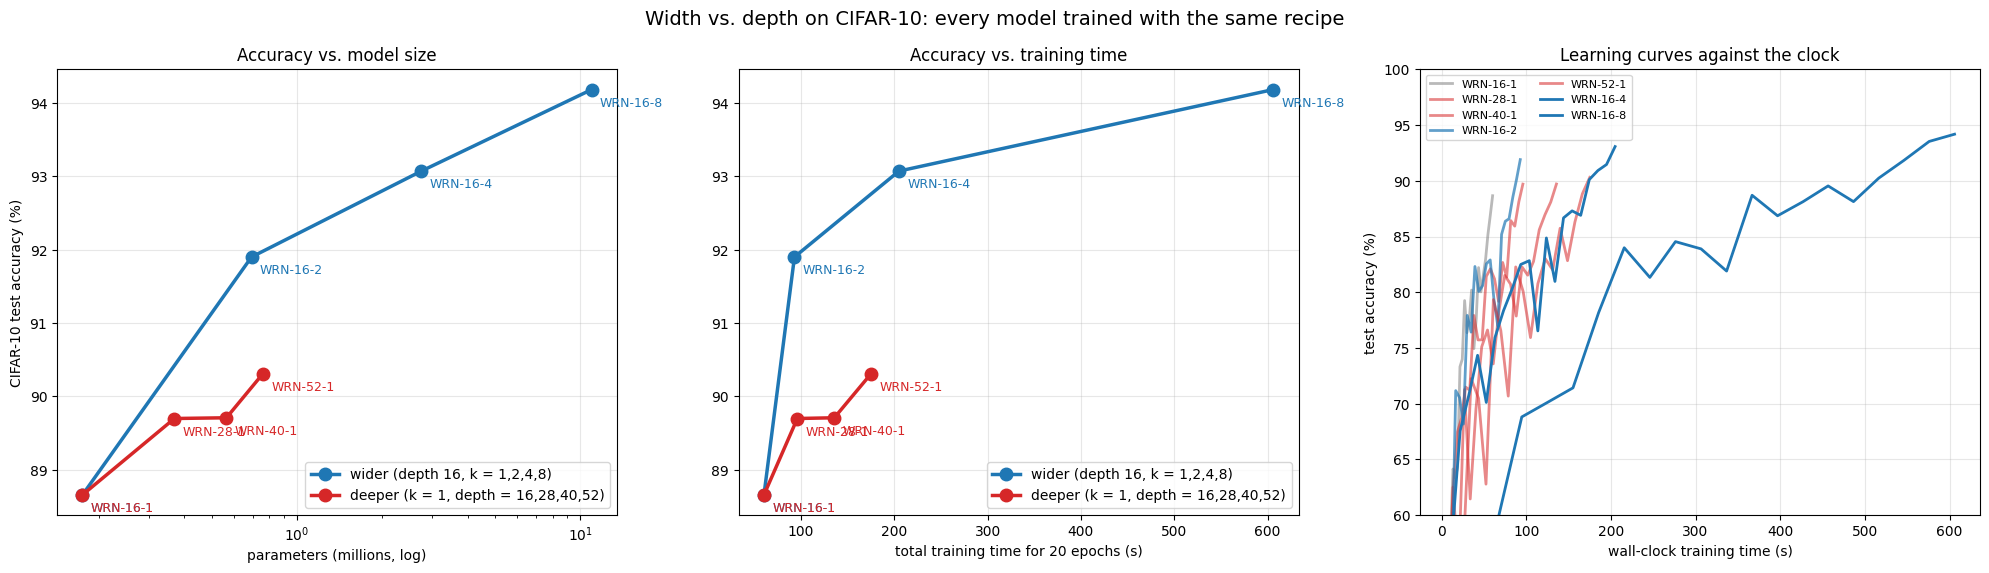

In [6]:
wide_names = [f'WRN-{d}-{k}' for d, k in WIDE_CONFIGS]
deep_names = [f'WRN-{d}-{k}' for d, k in DEEP_CONFIGS]
C_WIDE, C_DEEP = '#1f77b4', '#d62728'

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
for names, color, label in [(wide_names, C_WIDE, 'wider (depth 16, k = 1,2,4,8)'),
                            (deep_names, C_DEEP, 'deeper (k = 1, depth = 16,28,40,52)')]:
    p = [results[n]['params'] / 1e6 for n in names]
    t = [results[n]['time'][-1] for n in names]
    a = [results[n]['acc'][-1] * 100 for n in names]
    axes[0].plot(p, a, 'o-', color=color, lw=2.5, ms=9, label=label)
    axes[1].plot(t, a, 'o-', color=color, lw=2.5, ms=9, label=label)
    for n, pi, ti, ai in zip(names, p, t, a):
        axes[0].annotate(n, (pi, ai), textcoords='offset points', xytext=(6, -12), fontsize=9, color=color)
        axes[1].annotate(n, (ti, ai), textcoords='offset points', xytext=(6, -12), fontsize=9, color=color)
axes[0].set_xscale('log'); axes[0].set_xlabel('parameters (millions, log)'); axes[0].set_ylabel('CIFAR-10 test accuracy (%)')
axes[0].set_title('Accuracy vs. model size')
axes[1].set_xlabel(f'total training time for {EPOCHS} epochs (s)'); axes[1].set_title('Accuracy vs. training time')
for ax in axes[:2]:
    ax.grid(alpha=0.3); ax.legend(loc='lower right')

for n in sorted(results, key=lambda n: results[n]['params']):
    r = results[n]
    color = C_DEEP if r['k'] == 1 and r['depth'] > 16 else (C_WIDE if r['k'] > 1 else 'gray')
    axes[2].plot(r['time'], [a * 100 for a in r['acc']], lw=2, color=color, alpha=0.4 + 0.15 * min(r['k'], 4),
                 label=n)
axes[2].set_ylim(60, 100); axes[2].set_xlabel('wall-clock training time (s)'); axes[2].set_ylabel('test accuracy (%)')
axes[2].set_title('Learning curves against the clock'); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=8, ncol=2)
plt.suptitle('Width vs. depth on CIFAR-10: every model trained with the same recipe', fontsize=14)
plt.tight_layout(); plt.show()

In [7]:
# The head-to-head the paper is famous for: roughly equal parameter budgets, shallow-wide vs. deep-thin
pairs = [('WRN-16-2', 'WRN-40-1'), ('WRN-16-2', 'WRN-52-1')]
print(f'{"":22s}{"params":>9s}{"blocks":>8s}{"acc":>9s}{"time":>9s}')
for wide, deep in pairs:
    for n in (wide, deep):
        r = results[n]
        print(f'  {n:20s}{r["params"] / 1e6:8.2f}M{len(models[n].blocks):8d}{r["acc"][-1] * 100:8.2f}%{r["time"][-1]:8.1f}s')
    rw, rd = results[wide], results[deep]
    print(f'  -> {wide} vs {deep}: {(rw["acc"][-1] - rd["acc"][-1]) * 100:+.2f} pts accuracy, '
          f'{rd["time"][-1] / rw["time"][-1]:.2f}x faster to train\n')

best = max(results, key=lambda n: results[n]['acc'][-1])
rb = results[best]
print(f'Best model: {best} reached {rb["acc"][-1] * 100:.2f}% test accuracy '
      f'after {rb["time"][-1] / 60:.1f} min of training on one {torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"}.')

                         params  blocks      acc     time
  WRN-16-2                0.69M       6   91.90%    93.0s
  WRN-40-1                0.56M      18   89.71%   135.7s
  -> WRN-16-2 vs WRN-40-1: +2.19 pts accuracy, 1.46x faster to train

  WRN-16-2                0.69M       6   91.90%    93.0s
  WRN-52-1                0.76M      24   90.31%   175.1s
  -> WRN-16-2 vs WRN-52-1: +1.59 pts accuracy, 1.88x faster to train

Best model: WRN-16-8 reached 94.18% test accuracy after 10.1 min of training on one Tesla T4.


## 6. Lesion Study: Do All Those Blocks Actually Matter?

The paper's motivation is **diminishing feature reuse**: in a very deep ResNet, gradients can flow through the identity
shortcuts, so many residual blocks end up learning very little, and only a few blocks do the real work.

We can test this directly (a lesion study in the spirit of Veit et al., 2016). Take a trained network, **switch off one
residual block** (keep only its shortcut path) and measure how much test accuracy drops. Blocks that change resolution
have a 1×1 projection shortcut that is kept, so even those can be switched off.

- If a block is barely used, removing it costs almost nothing.
- If every block carries real features, every removal hurts.

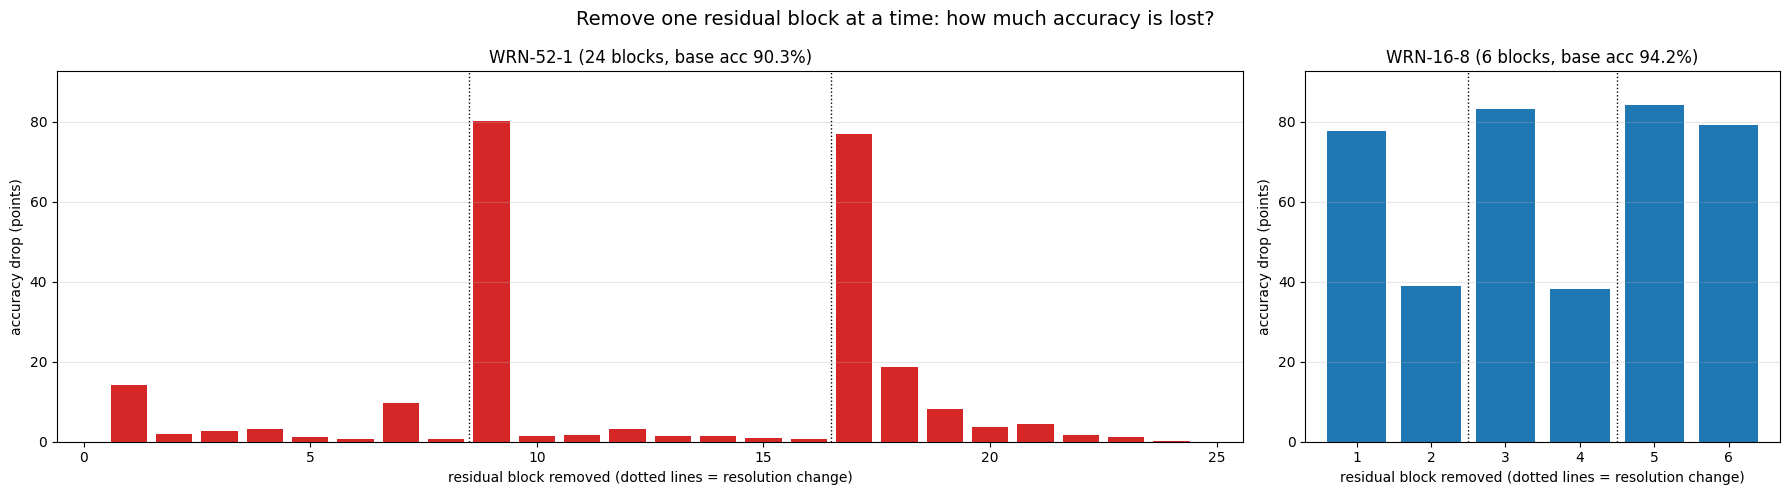

WRN-52-1: 5/24 blocks can be removed individually for < 1 pt accuracy loss (median drop 1.89 pts, max 80.14 pts)
WRN-16-8: 0/6 blocks can be removed individually for < 1 pt accuracy loss (median drop 78.37 pts, max 84.18 pts)


In [8]:
@torch.no_grad()
def lesion(model):
    base, _ = evaluate(model)
    drops = []
    for blk in model.blocks:
        blk.enabled = False
        acc, _ = evaluate(model)
        blk.enabled = True
        drops.append((base - acc) * 100)
    return base, np.array(drops)


lesion_models = ['WRN-52-1', 'WRN-16-8']
lesion_res = {n: lesion(models[n]) for n in lesion_models}

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [3, 1.2]})
for ax, n, color in zip(axes, lesion_models, [C_DEEP, C_WIDE]):
    base, drops = lesion_res[n]
    nb = len(drops); per_group = nb // 3
    bars = ax.bar(range(1, nb + 1), drops, color=color)
    for g in range(1, 3):
        ax.axvline(g * per_group + 0.5, color='k', ls=':', lw=1)
    ax.set_title(f'{n} ({nb} blocks, base acc {base * 100:.1f}%)')
    ax.set_xlabel('residual block removed (dotted lines = resolution change)'); ax.set_ylabel('accuracy drop (points)')
    ax.set_ylim(0, max(d.max() for _, d in lesion_res.values()) * 1.1); ax.grid(alpha=0.3, axis='y')
plt.suptitle('Remove one residual block at a time: how much accuracy is lost?', fontsize=14)
plt.tight_layout(); plt.show()

for n in lesion_models:
    base, drops = lesion_res[n]
    small = (drops < 1.0).sum()
    print(f'{n}: {small}/{len(drops)} blocks can be removed individually for < 1 pt accuracy loss '
          f'(median drop {np.median(drops):.2f} pts, max {drops.max():.2f} pts)')

## 7. What the Best Wide Network Sees

Predictions of the best model on random test images (green = correct, red = wrong), followed by the mistakes it
was **most confident** about, and the full confusion matrix.

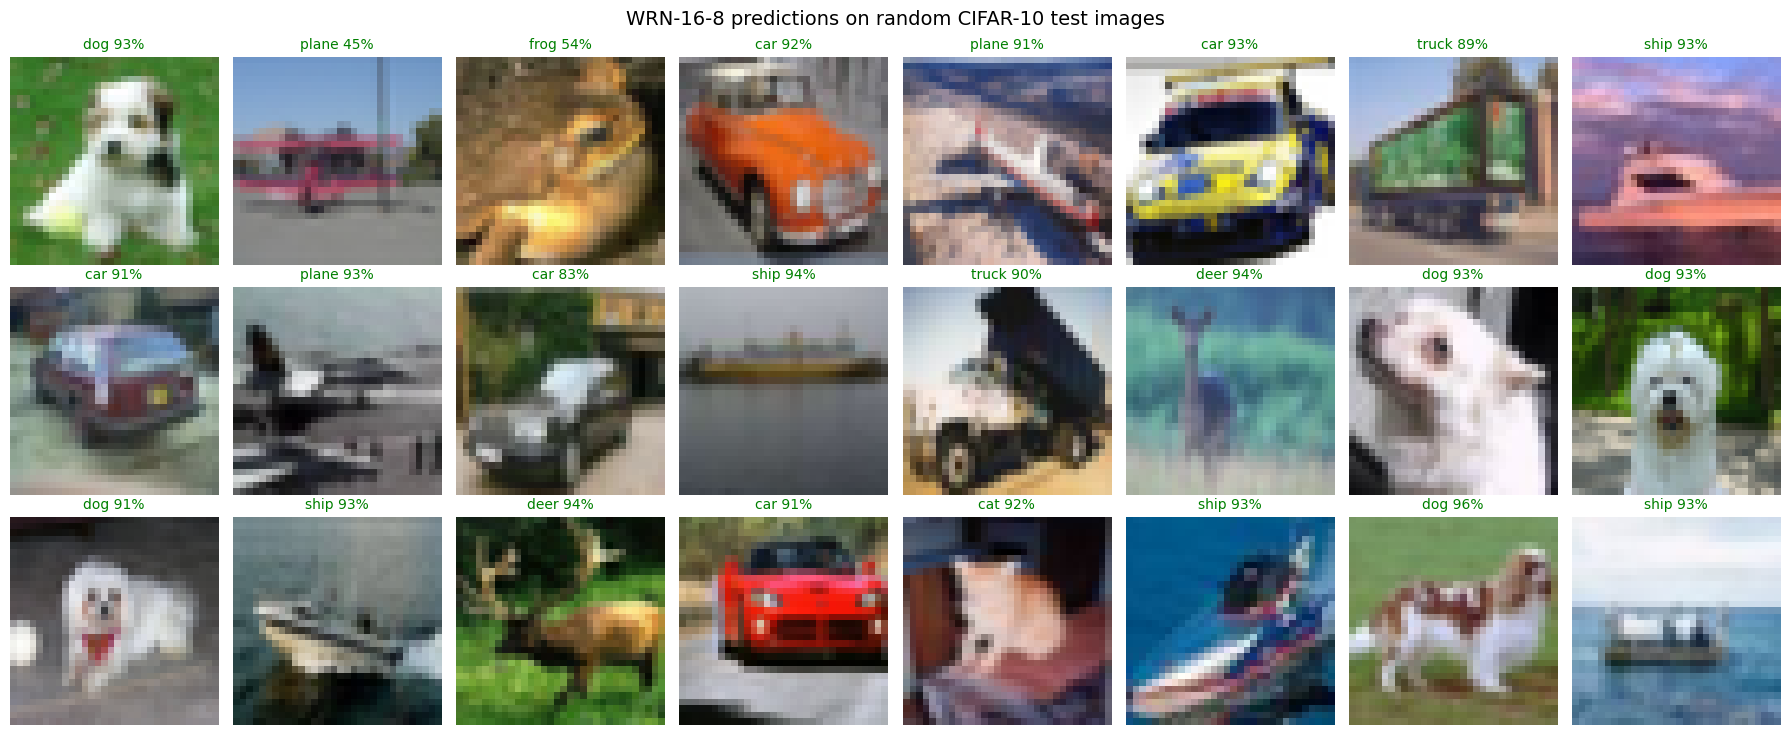

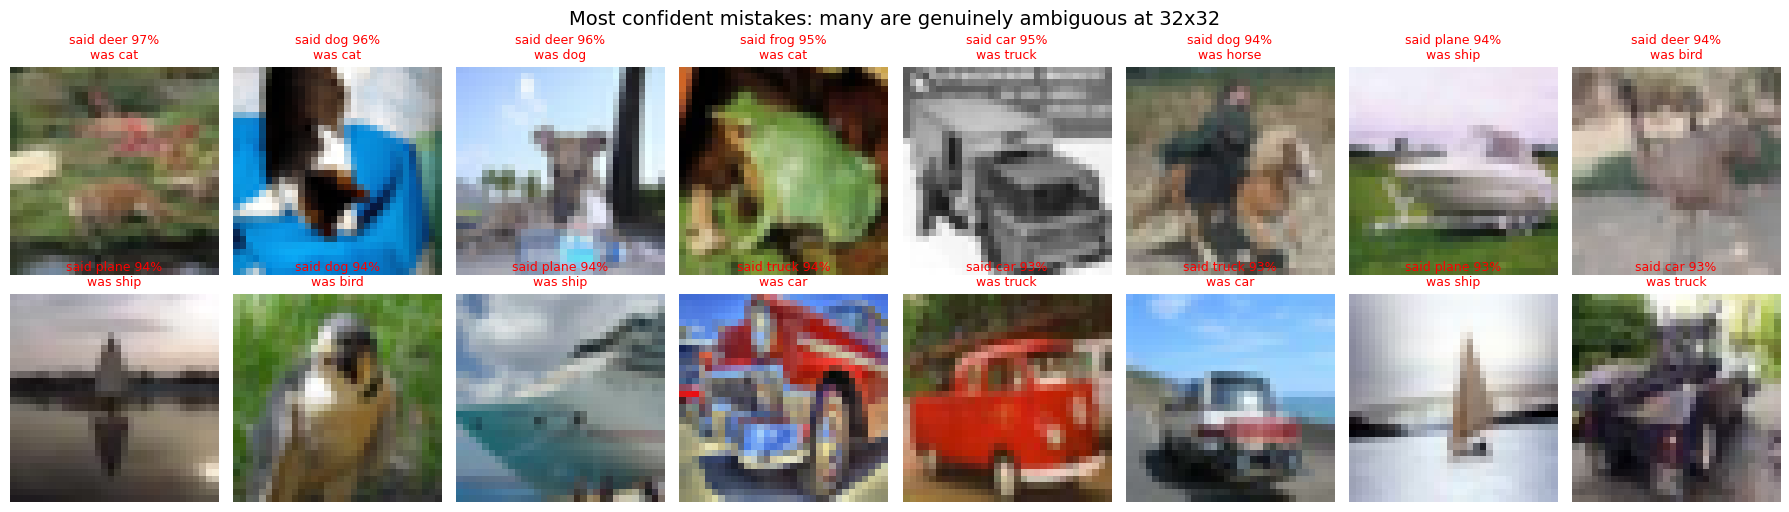

In [9]:
best_model = models[best]
_, logits = evaluate(best_model)
probs = logits.softmax(1).cpu()
pred = probs.argmax(1)
conf = probs.max(1).values
y_true = y_test

g = torch.Generator().manual_seed(1)
idx = torch.randperm(len(y_true), generator=g)[:24]
fig, axes = plt.subplots(3, 8, figsize=(18, 7.5))
for ax, i in zip(axes.flat, idx.tolist()):
    ax.imshow(x_test_u8[i].permute(1, 2, 0))
    ok = pred[i] == y_true[i]
    ax.set_title(f'{CLASSES[pred[i]]} {conf[i] * 100:.0f}%', color='green' if ok else 'red', fontsize=10)
    ax.axis('off')
plt.suptitle(f'{best} predictions on random CIFAR-10 test images', fontsize=14)
plt.tight_layout(); plt.show()

wrong = (pred != y_true).nonzero().squeeze(1)
worst = wrong[conf[wrong].argsort(descending=True)[:16]]
fig, axes = plt.subplots(2, 8, figsize=(18, 5.2))
for ax, i in zip(axes.flat, worst.tolist()):
    ax.imshow(x_test_u8[i].permute(1, 2, 0))
    ax.set_title(f'said {CLASSES[pred[i]]} {conf[i] * 100:.0f}%\nwas {CLASSES[y_true[i]]}', color='red', fontsize=9)
    ax.axis('off')
plt.suptitle('Most confident mistakes: many are genuinely ambiguous at 32x32', fontsize=14)
plt.tight_layout(); plt.show()

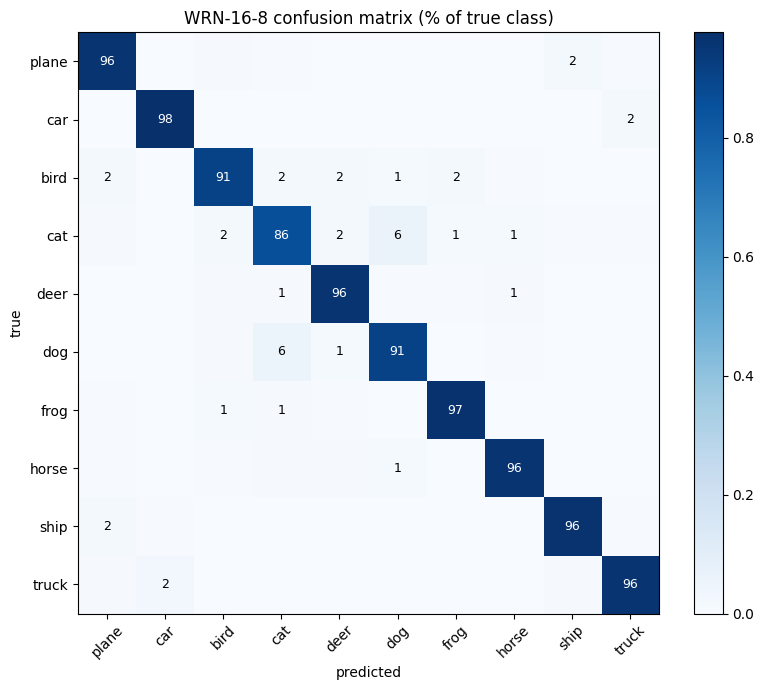

Per-class accuracy: plane 96.1%, car 97.7%, bird 90.6%, cat 86.2%, deer 95.6%, dog 90.8%, frog 96.7%, horse 95.8%, ship 96.5%, truck 95.8%
Most common confusion: cat -> dog (6.3% of cat images)


In [10]:
cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(y_true.tolist(), pred.tolist()):
    cm[t, p] += 1
cm_norm = cm.float() / cm.sum(1, keepdim=True)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm_norm, cmap='Blues')
ax.set_xticks(range(10), CLASSES, rotation=45); ax.set_yticks(range(10), CLASSES)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
for i in range(10):
    for j in range(10):
        v = cm_norm[i, j].item()
        if v >= 0.01:
            ax.text(j, i, f'{v * 100:.0f}', ha='center', va='center', color='white' if v > 0.5 else 'black', fontsize=9)
ax.set_title(f'{best} confusion matrix (% of true class)')
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class = cm.diag().float() / cm.sum(1)
print('Per-class accuracy:', ', '.join(f'{c} {a * 100:.1f}%' for c, a in zip(CLASSES, per_class)))
off = cm_norm.clone(); off.fill_diagonal_(0)
i, j = divmod(off.argmax().item(), 10)
print(f'Most common confusion: {CLASSES[i]} -> {CLASSES[j]} ({off[i, j] * 100:.1f}% of {CLASSES[i]} images)')

## 8. Summary

### What the run above shows

- **Width beat depth at a similar parameter budget.** WRN-16-2 (0.69M parameters, 6 blocks) scored about 2 points higher than WRN-40-1 (0.56M, 18 blocks) and about 1.5 points higher than WRN-52-1 (0.76M, 24 blocks), and trained 1.4-1.9× faster.
- **Going deeper at width 1 helped only a little:** from 6 to 24 blocks the accuracy rose by under 2 points, while the training time roughly tripled.
- **Going wider kept helping:** accuracy rose from about 89% (WRN-16-1) to about 94% (WRN-16-8, 10.96M parameters), which took about 10 minutes on the T4.
- **Lesion study:** in the 24-block thin network, a handful of blocks (5 in the saved run, 6 in a re-run) could be switched off one at a time with under 1 point of accuracy loss (median drop about 2 points). In the 6-block WRN-16-8 none could (median drop about 78 points, close to chance). This fits the idea of diminishing feature reuse, but the two networks have different depths, so it is suggestive and not a controlled test.
- **Mistakes:** the most common confusion is cat → dog (about 6% of cats).
- **Limits:** one seed per model and 20 epochs, so differences of a few tenths of a point are noise, and the saved numbers can shift slightly between runs. WRN-16-8 reached about 94%, below the paper's 200-epoch results, as expected for a 20-epoch run.

**Deliberate simplifications vs. the paper**
- 20 epochs with a one-cycle LR schedule and label smoothing, instead of 200 epochs with step decay (×0.2 at 60/120/160).
- Mixed-precision training; no dropout in the main comparison (the paper reports dropout as a further gain for wide nets).
- One seed per model, so differences of a few tenths of a point are within noise.
- The largest model here is WRN-16-8. The paper's best CIFAR-10 result is WRN-28-10 with 3.89% error.

In [11]:
print('=' * 72)
print('Wide Residual Networks -- reproduction summary (CIFAR-10, same recipe for all models)')
print('=' * 72)
print(f'{"model":10s}{"params":>9s}{"blocks":>8s}{"test acc":>10s}{"train time":>12s}')
for n in sorted(results, key=lambda n: (results[n]['k'], results[n]['depth'])):
    r = results[n]
    print(f'{n:10s}{r["params"] / 1e6:8.2f}M{len(models[n].blocks):8d}{r["acc"][-1] * 100:9.2f}%{r["time"][-1]:11.1f}s')
print('-' * 72)
for n in lesion_models:
    base, drops = lesion_res[n]
    print(f'Lesion {n:9s}: {(drops < 1.0).sum()}/{len(drops)} blocks removable for < 1 pt loss')
print(f'Best: {best} at {results[best]["acc"][-1] * 100:.2f}% in {results[best]["time"][-1] / 60:.1f} min of training')

Wide Residual Networks -- reproduction summary (CIFAR-10, same recipe for all models)
model        params  blocks  test acc  train time
WRN-16-1      0.18M       6    88.66%       60.4s
WRN-28-1      0.37M      12    89.70%       96.1s
WRN-40-1      0.56M      18    89.71%      135.7s
WRN-52-1      0.76M      24    90.31%      175.1s
WRN-16-2      0.69M       6    91.90%       93.0s
WRN-16-4      2.75M       6    93.07%      205.0s
WRN-16-8     10.96M       6    94.18%      605.9s
------------------------------------------------------------------------
Lesion WRN-52-1 : 5/24 blocks removable for < 1 pt loss
Lesion WRN-16-8 : 0/6 blocks removable for < 1 pt loss
Best: WRN-16-8 at 94.18% in 10.1 min of training
